# Financial complaint classification and response drafting

Financial institutions receive complaints about their services like payments or loans. Before a case can be reviewed, it must be assigned to the right team. That is not always straightforward from the customer's description: for example, a failed transfer may also mention a debit card or an unauthorized transaction.

In this notebook, I use complaints published by the Consumer Financial Protection Bureau (CFPB) to classify 7 product categories from their narratives. After training the classifiers, i use a language model to draft a response for review.

For the classifiers, I start with TF-IDF models, which are quite inexpensive, and then try a fine-tuning model to see whether a contextual model improves category predictions.

Dataset: [liri-uzh/cfpb-complaints-mini](https://huggingface.co/datasets/liri-uzh/cfpb-complaints-mini), based on the [CFPB Consumer Complaint Database](https://www.consumerfinance.gov/data-research/consumer-complaints/).


## 1. Dataset and preprocessing

### Environment

In [1]:
%pip -q install "transformers==4.57.1" "datasets==3.6.0" "accelerate==1.11.0" "sentence-transformers==5.1.2" "joblib" "sentencepiece"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 75.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 375.8/375.8 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 488.0/488.0 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 31.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires

In [2]:
import gc
import json
import random
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset, load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, classification_report, f1_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from transformers import (AutoModelForCausalLM, AutoModelForSequenceClassification,
                          AutoTokenizer, DataCollatorWithPadding, Trainer, TrainingArguments)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

SAVE_TO_DRIVE = False
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUTPUT_DIR = Path('/content/drive/MyDrive/Financial_Complaint_AI')
else:
    OUTPUT_DIR = Path('/content/Financial_Complaint_AI') if Path('/content').exists() else Path('./financial_complaint_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE)
print('Saved files:', OUTPUT_DIR)

Device: cuda
Saved files: /content/Financial_Complaint_AI


### Dataset

The downloaded dataset contains the complaint narrative (`text`), the final product category (`label`) and the original product name (`product_raw`). I use the narrative to predict `label`. Including `product_raw` as a feature would reveal information very close to the answer, so I keep it only to inspect how the products were grouped.

The dataset is not a representation of the real distribution of complaints in the US, as the dataset card has a limit on examples per category.

Sources: [dataset card](https://huggingface.co/datasets/liri-uzh/cfpb-complaints-mini)

In [3]:
raw = load_dataset('liri-uzh/cfpb-complaints-mini')
print(raw)

train_raw = raw['train'].to_pandas()[['text', 'label', 'product_raw']].copy()
test_raw = raw['test'].to_pandas()[['text', 'label', 'product_raw']].copy()

print('\nTraining shape:', train_raw.shape)
print('Test shape:', test_raw.shape)
print('\nExample labels and original product names (no customer text):')
display(train_raw[['label', 'product_raw']].head(5))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

cfpb_mini_train.parquet:   0%|          | 0.00/4.25M [00:00<?, ?B/s]

cfpb_mini_test.parquet:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/6469 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1635 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'product_raw'],
        num_rows: 6469
    })
    test: Dataset({
        features: ['text', 'label', 'product_raw'],
        num_rows: 1635
    })
})

Training shape: (6469, 3)
Test shape: (1635, 3)

Example labels and original product names (no customer text):


,label,product_raw
0,student_loan,Student loan
1,student_loan,Student loan
2,debt_collection,Debt collection
3,debt_collection,Debt collection
4,credit_reporting,"Credit reporting, credit repair services, or o..."


The original dataset already provides separate train and test partitions. The narrative (`text`) is the input, and the consolidated product category (`label`) is the target.

The splits contain 6,469 training and 1,635 test sets.

It can be seen that `label`and `product_raw` do not have exactly the same information (`product_raw` may have more information). I use part of the training split to create a validation set.

### Data quality and product categories

Before cleaning the texts, I check for missing values, repeated narratives and class imbalance. I also compare the consolidated labels with their original product names, and inspect a few examples to see what the descriptions look like.

In [4]:
missing = train_raw.isna().sum().rename('missing')
empty_text = train_raw['text'].fillna('').str.strip().eq('').sum()
exact_duplicates = train_raw['text'].fillna('').duplicated().sum()

print('Missing values by column:')
display(missing.to_frame())
print('Empty narratives:', empty_text)
print('Repeated narratives in training:', exact_duplicates)

Missing values by column:


,missing
text,0
label,0
product_raw,0


Empty narratives: 0
Repeated narratives in training: 105


There are no missing fields or empty narratives in the raw training split, but 105 texts are repeated.

,complaints
label,
credit_reporting,819
credit_card,862
debt_collection,948
student_loan,960
bank_account,960
money_transfer,960
mortgage,960


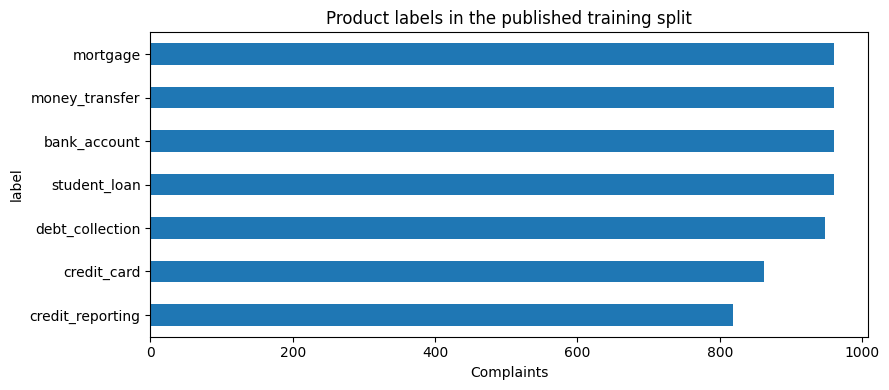

In [5]:
counts = train_raw['label'].value_counts().sort_values()
display(counts.rename('complaints').to_frame())
counts.plot.barh(figsize=(9, 4), title='Product labels in the published training split')
plt.xlabel('Complaints')
plt.tight_layout()
plt.show()

The classes are reasonably balanced, where 5 of them are around 950-960 complaints, while `credit_reporting` has 819 and `credit_card` 862.

In [6]:
preview = train_raw[['text', 'label', 'product_raw']].sample(10, random_state=SEED).copy()
preview['text'] = preview['text'].str.slice(0, 120) + '...'
display(preview.reset_index(drop=True))

,text,label,product_raw
0,Wells Fargo Credit Card XXXX Customer Service ...,credit_card,Credit card or prepaid card
1,I deposited a check on XX/XX/2023 of the amoun...,bank_account,Checking or savings account
2,XXXX XXXX XXXX XXXX was a predator company who...,money_transfer,"Money transfer, virtual currency, or money ser..."
3,I was offering tennis lessons and was sent a f...,bank_account,Checking or savings account
4,"BMO BANK N.A., Account # : XXXX Open Date : XX...",bank_account,Checking or savings account
5,"Upon careful review, I want to clarify that th...",mortgage,Mortgage
6,I transfered XXXX in total to marcus account i...,bank_account,Checking or savings account
7,I have had 3 separate phone calls in the last ...,student_loan,Student loan
8,I was sent his debt collection and given a cer...,debt_collection,Debt collection
9,I transferred some funds into a savings accoun...,money_transfer,"Money transfer, virtual currency, or money ser..."


 This table confirms that the original product names have been combined to create the label.

 I remove duplicate texts before splitting the data into training and validation. I do this because, identical complaints could appear in both sets, making the validation results less reliable. Removing duplicates also prevents repeated texts from having more influence during training.

Word counts (training split):


,words
count,6469.0
mean,222.0
std,266.0
min,3.0
50%,153.0
75%,273.0
90%,448.0
95%,618.0
max,5659.0


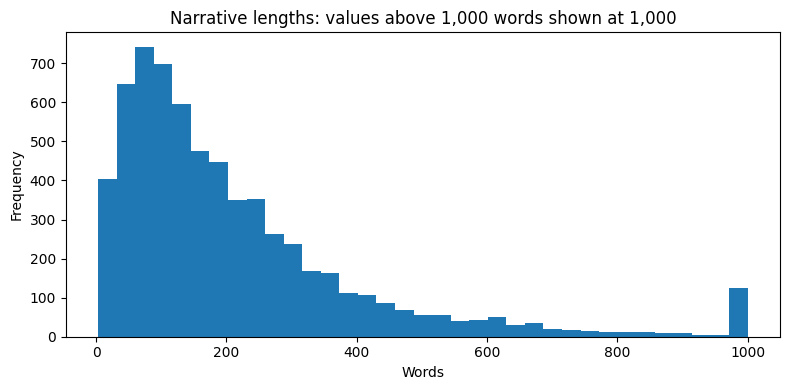

Typical narrative length in words by product:


,median,mean
label,,
bank_account,164.0,227.4
credit_card,136.0,186.1
credit_reporting,109.0,221.7
debt_collection,133.0,193.4
money_transfer,167.5,225.5
mortgage,200.5,286.1
student_loan,164.0,210.4


In [7]:
train_words = train_raw['text'].fillna('').str.split().str.len()
print('Word counts (training split):')
display(train_words.describe(percentiles=[0.50, 0.75, 0.90, 0.95]).round(0).to_frame('words'))

train_words.clip(upper=1000).plot.hist(bins=35, figsize=(8, 4))
plt.title('Narrative lengths: values above 1,000 words shown at 1,000')
plt.xlabel('Words')
plt.tight_layout()
plt.show()

print('Typical narrative length in words by product:')
display(train_raw.assign(words=train_words).groupby('label')['words']
        .agg(['median', 'mean']).round(1))

Complaint length is skewed. The median is 153 words, the mean 222, and the longest text contains 5,659 words. So lengths vary considerably.

Mortgage complaints have the longest median (200.5 words), while credit reporting has the shortest (109 words).

The histogram makes it clear why a fixed sequence limit could discard useful details in some cases.

The Transformer will use a fixed maximum input of 384 tokens, therefore longer texts will be truncated. This keeps training manageable, although some detail may be lost.

### Cleaning and validation split

I normalize repeated whitespaces and remove duplicated or blank narratives before creating the validation split. I also check that no training narrative appears verbatim in the test split. I leave spelling, punctuation and negations intact, because words such as *not* may change their meaning. The validation set is stratified by product category (15% of clean training data).

I retain short texts because even a brief complaint may identify a product.

In [8]:
def clean_text(frame):
    frame = frame.copy()
    frame['text'] = (frame['text'].fillna('').str.replace(r'\s+', ' ', regex=True).str.strip())
    return frame

train_clean = clean_text(train_raw)
test_df = clean_text(test_raw)

empty_count = int(train_clean['text'].eq('').sum())
train_clean = train_clean[train_clean['text'].ne('')]
duplicate_count = int(train_clean['text'].duplicated().sum())
train_clean = train_clean.drop_duplicates(subset='text')
test_overlap_count = int(train_clean['text'].isin(set(test_df['text'])).sum())
train_clean = train_clean[~train_clean['text'].isin(set(test_df['text']))].reset_index(drop=True)

print('Removed empty training narratives:', empty_count)
print('Removed duplicate training narratives:', duplicate_count)
print('Removed training texts also found in test:', test_overlap_count)
print('Empty test narratives:', int(test_df['text'].eq('').sum()))
assert test_df['text'].ne('').all(), 'Inspect blank test texts before evaluating.'

train_df, val_df = train_test_split(train_clean, test_size=0.15,
                                    random_state=SEED, stratify=train_clean['label'])
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
assert set(train_df.text).isdisjoint(set(val_df.text))
assert set(train_df.text).isdisjoint(set(test_df.text))
assert set(val_df.text).isdisjoint(set(test_df.text))
labels = sorted(train_df['label'].unique())
label_to_id = {label: i for i, label in enumerate(labels)}
id_to_label = {i: label for label, i in label_to_id.items()}

print(f'Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}')
print('Categories:', labels)

Removed empty training narratives: 0
Removed duplicate training narratives: 116
Removed training texts also found in test: 0
Empty test narratives: 0
Train: 5,400 | Validation: 953 | Test: 1,635
Categories: ['bank_account', 'credit_card', 'credit_reporting', 'debt_collection', 'money_transfer', 'mortgage', 'student_loan']


Whitespace normalization produces 116 exact duplicates, slightly more than were visible in the raw texts. No cleaned training texts are exact matches for the published test texts. The final split contains 5,400 training, 953 validation and 1,635 test complaints.

## 2. TF-IDF classifiers

I first fit TF-IDF with logistic regression. Its input consists of word unigrams and bigrams, so it can use the entire narrative without a Transformer token limit. I then compare a larger vocabulary and two linear SVM alternatives, including character n-grams. All configurations use the same training and validation sets.

In [9]:
baseline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=30_000),
    LogisticRegression(max_iter=1000))
baseline.fit(train_df['text'], train_df['label'])

val_base_pred = baseline.predict(val_df['text'])
base_val_f1 = f1_score(val_df['label'], val_base_pred, average='macro')
print('Baseline validation accuracy:', round(accuracy_score(val_df['label'], val_base_pred), 4))
print('Baseline validation macro-F1:', round(base_val_f1, 4))

Baseline validation accuracy: 0.8374
Baseline validation macro-F1: 0.836


The first baseline reaches 0.836 macro-F1 and 0.8374 accuracy on validation. Considering how little training this model requires, it is already a useful result.

In [10]:
from sklearn.svm import LinearSVC

sparse_models = {'TF-IDF original': baseline}
sparse_candidates = {
    'TF-IDF more words': make_pipeline(            # 1 or 2-grams
        TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=80_000, sublinear_tf=True),
        LogisticRegression(C=2.0, max_iter=1000)),
    'TF-IDF words + SVM': make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=80_000, sublinear_tf=True),
        LinearSVC(C=1.0, random_state=SEED)),
    'TF-IDF characters + SVM': make_pipeline(      # 3, 4 and 5 characters
        TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=3, max_features=80_000, sublinear_tf=True),
        LinearSVC(C=1.0, random_state=SEED))}

for name, candidate in sparse_candidates.items():
    candidate.fit(train_df['text'], train_df['label'])
    sparse_models[name] = candidate

sparse_results = []
for name, candidate in sparse_models.items():
    predictions = candidate.predict(val_df['text'])
    sparse_results.append({
        'model': name,
        'validation_macro_f1': f1_score(val_df['label'], predictions, average='macro'),
        'validation_accuracy': accuracy_score(val_df['label'], predictions)})

sparse_scores = pd.DataFrame(sparse_results).sort_values('validation_macro_f1',
                                                         ascending=False).reset_index(drop=True)
display(sparse_scores.round(4))
print('\nBest sparse classifier on validation:', sparse_scores.loc[0, 'model'])

,model,validation_macro_f1,validation_accuracy
0,TF-IDF words + SVM,0.8465,0.8468
1,TF-IDF more words,0.8400,0.8405
2,TF-IDF characters + SVM,0.8380,0.8384
3,TF-IDF original,0.8360,0.8374



Best sparse classifier on validation: TF-IDF words + SVM


The table above ranks the sparse models on validation macro-F1. It can be seen that the best sparse classifier is TF-IDF words + SVM. I will use it to compare it with DeBERTa.

Compared to the baseline model, it slightly improved its performance.

## 3. Fine-tuning DeBERTa-v3-base

Unlike TF-IDF, DeBERTa-v3-base can use contextual representations of the complaint. I fix the input length at 384 tokens to balance between context and GPU memory, not because it is optimal.

Each epoch is evaluated on validation, and the checkpoint with the highest macro-F1 is kept. We use macro-F1 instead of accuracy because it gives equal importance to every category, even when some categories like *credit_reporting* contain fewer complaints.

Early stopping avoids training through several unproductive epochs.

In [11]:
from transformers import EarlyStoppingCallback, set_seed

if DEVICE != 'cuda':
    raise RuntimeError('Enable a GPU in Colab before fine-tuning DeBERTa.')

MODEL_NAME = 'microsoft/deberta-v3-base'
MAX_LENGTH = 384
BATCH_SIZE = 4
GRADIENT_ACCUMULATION = 4
EPOCHS = 8
LEARNING_RATE = 2e-5

set_seed(SEED)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_hf_dataset(frame):
    ds = Dataset.from_pandas(frame[['text', 'label']], preserve_index=False)
    ds = ds.map(lambda batch: tokenizer(batch['text'], truncation=True,
                                        max_length=MAX_LENGTH), batched=True)
    return ds.map(lambda row: {'labels': label_to_id[row['label']]},
                  remove_columns=['text', 'label'])

hf_train = to_hf_dataset(train_df)
hf_val = to_hf_dataset(val_df)
hf_test = to_hf_dataset(test_df)
collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(labels), id2label=id_to_label, label2id=label_to_id)

def compute_metrics(result):
    logits, gold = result
    pred = logits.argmax(axis=1)
    return {'accuracy': accuracy_score(gold, pred),
            'macro_f1': f1_score(gold, pred, average='macro')}

args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / 'deberta_checkpoints'),
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION,
    per_device_eval_batch_size=16,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    warmup_ratio=0.1,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='macro_f1',
    greater_is_better=True,
    save_total_limit=2,
    logging_strategy='epoch',
    fp16=True,
    report_to='none',
    seed=SEED)

trainer = Trainer(
    model=model, args=args, train_dataset=hf_train, eval_dataset=hf_val,
    processing_class=tokenizer, data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
trainer.train()

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:564: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


Map:   0%|          | 0/5400 [00:00<?, ? examples/s]

...

pytorch_model.bin:   0%|          | 0.00/371M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/371M [00:00<?, ?B/s]

Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/deberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.412400,0.732591,0.763903,0.762857
2,0.661400,0.575196,0.820567,0.817759
3,0.497100,0.570607,0.827912,0.826118
4,0.375000,0.540902,0.850997,0.848617
5,0.295200,0.556158,0.852046,0.850075
6,0.231300,0.574583,0.854145,0.851490
7,0.174700,0.658679,0.849948,0.848546
8,0.140400,0.651979,0.859391,0.857784


TrainOutput(global_step=2704, training_loss=0.4734344228484927, metrics={'train_runtime': 2210.6315, 'train_samples_per_second': 19.542, 'train_steps_per_second': 1.223, 'total_flos': 7430394113283840.0, 'train_loss': 0.4734344228484927, 'epoch': 8.0})

### Validation curve

The next plot shows macro-F1 after each epoch. The best checkpoint is selected using these validation values, not the training loss. I inspect the curve to see whether performance continues improving or has started to level off.

,epoch,eval_macro_f1,eval_loss
1,1.0,0.7629,0.7326
3,2.0,0.8178,0.5752
5,3.0,0.8261,0.5706
7,4.0,0.8486,0.5409
9,5.0,0.8501,0.5562
11,6.0,0.8515,0.5746
13,7.0,0.8485,0.6587
15,8.0,0.8578,0.6520


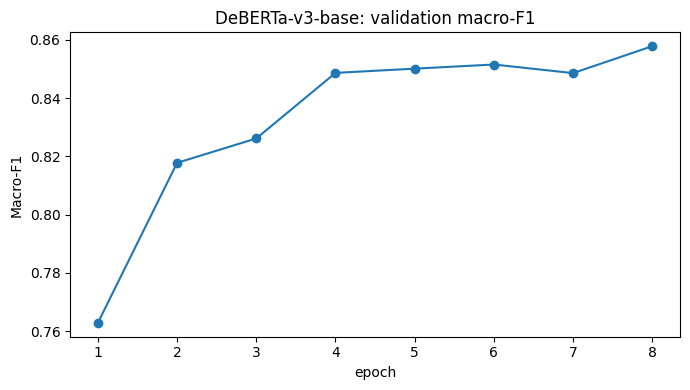

Best validation epoch: 8
Best validation macro-F1: 0.8578


In [12]:
history = pd.DataFrame(trainer.state.log_history)
epoch_scores = history.dropna(subset=['eval_macro_f1'])[
    ['epoch', 'eval_macro_f1', 'eval_loss']].copy()
display(epoch_scores.round(4))
epoch_scores.plot(x='epoch', y='eval_macro_f1', marker='o', legend=False,
                  figsize=(7, 4), title='DeBERTa-v3-base: validation macro-F1')
plt.ylabel('Macro-F1')
plt.tight_layout()
plt.show()

best_row = epoch_scores.loc[epoch_scores['eval_macro_f1'].idxmax()]
print(f"Best validation epoch: {best_row['epoch']:.0f}")
print(f"Best validation macro-F1: {best_row['eval_macro_f1']:.4f}")

DeBERTa reaches its highest validation macro-F1 of 0.8578 at epoch 8.

Macto-F1 stabilizes after reaching 4 epochs, after which results change more slowly.

However, the validation loss starts increasing after epoch 4, even though macro-F1 still improves slightly. This suggests that the model may be becoming more confident without improving its predictions by much.

## 4. Model comparison and test results

I compare all trained classifiers using validation macro-F1. After choosing the highest-ranked model, I evaluate it once on the published test set. I also report the original TF-IDF reference on test for context.

In [13]:
deberta_val_output = trainer.predict(hf_val)
deberta_val_pred = np.array([id_to_label[i] for i in
                             deberta_val_output.predictions.argmax(axis=1)])
deberta_val_f1 = f1_score(val_df['label'], deberta_val_pred, average='macro')

validation_results = pd.concat([
    sparse_scores,
    pd.DataFrame([{
        'model': 'DeBERTa-v3-base',
        'validation_macro_f1': deberta_val_f1,
        'validation_accuracy': accuracy_score(val_df['label'], deberta_val_pred)}])],
                               ignore_index=True).sort_values('validation_macro_f1',
                                                              ascending=False).reset_index(drop=True)
display(validation_results.round(4))
BEST_MODEL_NAME = validation_results.loc[0, 'model']
print('\nSelected on validation:', BEST_MODEL_NAME)

baseline_test_pred = baseline.predict(test_df['text'])
print('\nOriginal TF-IDF test macro-F1:', round(f1_score(test_df['label'], baseline_test_pred,
                                                     average='macro'), 4))

CLASSIFIER_DIR = OUTPUT_DIR / 'deberta_classifier'
trainer.save_model(str(CLASSIFIER_DIR))
tokenizer.save_pretrained(str(CLASSIFIER_DIR))
joblib.dump(baseline, OUTPUT_DIR / 'tfidf_logreg.joblib')

if BEST_MODEL_NAME == 'DeBERTa-v3-base':
    test_output = trainer.predict(hf_test)
    final_pred = np.array([id_to_label[i] for i in test_output.predictions.argmax(axis=1)])
    SELECTED_MODEL = 'deberta'
else:
    selected_sparse = sparse_models[BEST_MODEL_NAME]
    final_pred = selected_sparse.predict(test_df['text'])
    joblib.dump(selected_sparse, OUTPUT_DIR / 'selected_sparse_classifier.joblib')
    SELECTED_MODEL = 'sparse'

print('\nSelected-model test accuracy:', round(accuracy_score(test_df['label'], final_pred), 4))
print('Selected-model test macro-F1:', round(f1_score(test_df['label'], final_pred,
                                                       average='macro'), 4))
print(classification_report(test_df['label'], final_pred, labels=labels,
                            zero_division=0))

,model,validation_macro_f1,validation_accuracy
0,DeBERTa-v3-base,0.8578,0.8594
1,TF-IDF words + SVM,0.8465,0.8468
2,TF-IDF more words,0.8400,0.8405
3,TF-IDF characters + SVM,0.8380,0.8384
4,TF-IDF original,0.8360,0.8374



Selected on validation: DeBERTa-v3-base

Original TF-IDF test macro-F1: 0.8348



Selected-model test accuracy: 0.852
Selected-model test macro-F1: 0.8517
                  precision    recall  f1-score   support

    bank_account       0.77      0.75      0.76       240
     credit_card       0.85      0.84      0.84       219
credit_reporting       0.85      0.83      0.84       216
 debt_collection       0.82      0.87      0.84       240
  money_transfer       0.79      0.79      0.79       240
        mortgage       0.94      0.93      0.94       240
    student_loan       0.96      0.95      0.96       240

        accuracy                           0.85      1635
       macro avg       0.85      0.85      0.85      1635
    weighted avg       0.85      0.85      0.85      1635



Out of all the models, the selected classifier is DeBERTa-v3-base, as it achieves the best results. We will be using it from now on.

We could have also chosen TF-IDF + SVM if we valued training time over the small increase in performance.

The model manages to classify `student_loan` the best out of the 7 categories, with F1-score of 0.96, followed by `mortgage` (0.94).

In contrast, the model does a weaker job at classifying bank account (0.76) and money transfer (0.79).

### Classification errors

Now we observe which products are confused by using a Confusion Matrix.

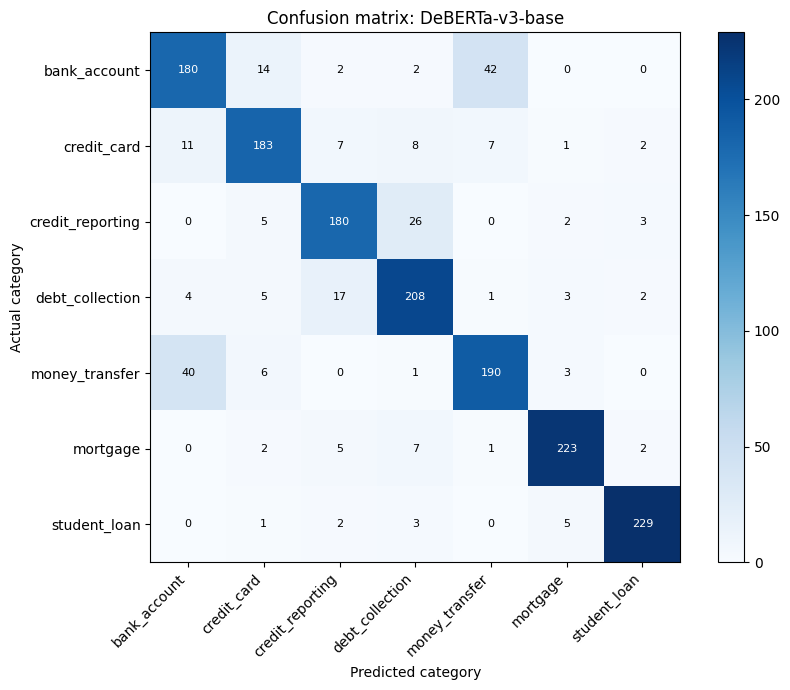

In [14]:
cm = confusion_matrix(test_df['label'], final_pred, labels=labels)
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(labels)), labels=labels, rotation=45, ha='right')
ax.set_yticks(range(len(labels)), labels=labels)
ax.set_xlabel('Predicted category')
ax.set_ylabel('Actual category')
ax.set_title(f'Confusion matrix: {BEST_MODEL_NAME}')
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=8,
                color='white' if cm[i, j] > cm.max()/2 else 'black')
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

In [15]:
errors = pd.DataFrame({'actual': test_df['label'], 'predicted': final_pred})
errors = errors[errors['actual'] != errors['predicted']]
print('Incorrect classifications:', len(errors))

Incorrect classifications: 242


The DeBERTa-v3-base model makes 242 errors on test. The main confusion is between money_transfer and bank_account, where 42 complaints are wrongfully labelled as money transfer instead of bank account complaints; followed by 40 transfer complaints labelled as bank-account.

As for credit reporting, there are 26 wrongfully labeled as debt collection.

### Sending uncertain cases for review

Instead of sending all of the predictions made by the model directly to a team, I use the model's highest softmax score as a confidence score to send the worst predictions to a manual review.

I take the 20th percentile of scores on validation, and complaints below that cut-off are flagged for a manual review. Those above it can move to the next stage.

In [16]:
def softmax_numpy(logits):
    shifted = logits - logits.max(axis=1, keepdims=True)
    exp = np.exp(shifted)
    return exp / exp.sum(axis=1, keepdims=True)

val_scores = softmax_numpy(deberta_val_output.predictions).max(axis=1)
test_scores = softmax_numpy(test_output.predictions).max(axis=1)
ROUTING_THRESHOLD = float(np.quantile(val_scores, 0.20))
test_auto = test_scores >= ROUTING_THRESHOLD
print('Validation review threshold:', round(ROUTING_THRESHOLD, 3))
print('Automatically routed on test:', f'{test_auto.mean():.1%}')
if test_auto.any():
    print('Accuracy on automatically routed test cases:',
          round(accuracy_score(test_df['label'][test_auto], final_pred[test_auto]), 4))
print('Incorrect automatic routes:', int(((final_pred != test_df['label'].to_numpy())
                                            & test_auto).sum()))

with open(OUTPUT_DIR / 'classifier_selection.json', 'w') as f:
    json.dump({'model': BEST_MODEL_NAME, 'max_length': MAX_LENGTH if SELECTED_MODEL == 'deberta' else None,
               'review_threshold': ROUTING_THRESHOLD, 'threshold_source': 'validation'}, f, indent=2)

del trainer, model
if DEVICE == 'cuda':
    torch.cuda.empty_cache()
gc.collect()

Validation review threshold: 0.989
Automatically routed on test: 79.4%
Accuracy on automatically routed test cases: 0.923
Incorrect automatic routes: 100


5098

We can see that the threshold selected is 0.989. With this value, it allows 79.4% of test complaints through, with 92.3% accuracy among those cases. That is better than routing everything automatically, but it still sends 100 complaints with a wrong category, even though the model assigned them a high confidence score. This shows that confidence is not enough to guarantee a correct prediction.

## 5. Retrieving public guidance and drafting a response

The classifier tells me which product a complaint probably belongs to, but it does not tell an employee how that problem should be handled. That is why I want the language model to have some information that an employee could open and check.

I retrieve a small number of texts form [Ask CFPB pages](https://www.consumerfinance.gov/ask-cfpb/). I am keeping 7 articles for each of the 7 product categories (49 in total).

Each text includes an ID, its category, a title, a summary note about how to solve the problem and a URL to identify the article.

In [23]:

knowledge_base = [
    {'id': 'CFPB01', 'category': 'bank_account',
     'title': 'Unauthorized bank-account transactions',
     'text': 'For an unrecognized withdrawal or electronic transaction, contact the bank or credit union promptly, explain the transaction in question and ask for an investigation. The applicable protections depend on the type of payment and when it was reported.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/how-do-i-get-my-money-back-after-i-discover-an-unauthorized-transaction-or-money-missing-from-my-bank-account-en-1017/'},
    {'id': 'CFPB02', 'category': 'bank_account',
     'title': 'Checking-account maintenance fees',
     'text': 'Maintenance fees and any conditions for avoiding them should be explained in the account terms. A customer questioning a fee can check their account agreement and ask the institution to explain the charge.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/why-am-i-being-charged-a-monthly-maintenance-fee-for-my-bank-or-credit-union-account-en-2151/'},
    {'id': 'CFPB15', 'category': 'bank_account',
     'title': 'Account closure by a bank or credit union',
     'text': 'A bank or credit union may close a checking account without the customer requesting closure. The circumstances and any notice requirements can depend on the account history and state law.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/the-bankcredit-union-closed-my-checking-account-even-though-i-did-not-want-them-to-can-the-bankcredit-union-do-that-en-959/'},

    {'id': 'CFPB03', 'category': 'credit_card',
     'title': 'Disputing a credit-card charge',
     'text': 'When a card statement contains a billing error, contact the card issuer and review its written dispute instructions. Keep the statement and copies of dispute correspondence. A dispute does not automatically establish that the charge will be removed.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/how-do-i-dispute-a-charge-on-my-credit-card-bill-en-61/'},
    {'id': 'CFPB04', 'category': 'credit_card',
     'title': 'Unauthorized credit-card charges',
     'text': 'Report a lost or stolen credit card or unrecognized charge to the issuer. Liability for unauthorized credit-card charges depends on the circumstances, including whether the card itself was lost.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/am-i-responsible-for-unauthorized-charges-if-my-credit-cards-are-lost-or-stolen-en-29/'},
    {'id': 'CFPB16', 'category': 'credit_card',
     'title': 'Credit-card payment missing from a statement',
     'text': 'When a payment is missing from a credit-card statement, the consumer can contact the issuer and follow its written billing-error dispute instructions. Records of the payment and statement are useful.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-should-i-do-if-my-payment-does-not-show-on-my-credit-card-statement-en-77/'},

    {'id': 'CFPB05', 'category': 'credit_reporting',
     'title': 'Disputing incorrect credit-report information',
     'text': 'A consumer can dispute inaccurate information with the credit reporting company and with the organization that supplied the information. The consumer should identify the disputed entry and provide supporting information.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/how-do-i-dispute-an-error-on-my-credit-report-en-314/'},
    {'id': 'CFPB06', 'category': 'credit_reporting',
     'title': 'Unfamiliar creditors on a credit report',
     'text': 'An unfamiliar company name on a credit report is not necessarily an error; a debt may have been transferred or reported under a different issuer. If the entry appears incorrect, it can be disputed.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/should-i-dispute-a-creditor-on-my-credit-report-if-i-dont-recognize-the-company-en-1331/'},
    {'id': 'CFPB17', 'category': 'credit_reporting',
     'title': 'Unresolved credit-report disputes',
     'text': 'If a credit reporting company has not adequately addressed a dispute, the consumer has options for challenging incomplete or incorrect report information and may include a statement of dispute.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-if-i-disagree-with-the-results-of-my-credit-report-dispute-en-1327/'},

    {'id': 'CFPB07', 'category': 'debt_collection',
     'title': 'Disputing a debt collection claim',
     'text': 'A consumer who believes a debt is not owed or the amount is wrong can dispute it with the collector. The validation notice and written communications help establish what is being claimed and how to request verification.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-can-i-do-if-a-debt-collector-contacts-me-about-a-debt-i-already-paid-or-dont-think-i-owe-en-1403/'},
    {'id': 'CFPB08', 'category': 'debt_collection',
     'title': 'Asking a debt collector to stop contact',
     'text': 'Consumers may ask debt collectors in writing to stop contacting them. Ending contact does not necessarily cancel a valid debt, so a dispute about whether the debt is owed is a separate question.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/how-do-i-get-a-debt-collector-to-stop-contacting-me-en-1411/'},
    {'id': 'CFPB18', 'category': 'debt_collection',
     'title': 'Excessive calls from debt collectors',
     'text': 'Debt collectors are subject to limits on repeated or inconvenient calls. Keeping dates, times and records of contacts can help document a problem with how a collector communicates.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/when-and-how-often-can-a-debt-collector-call-me-on-the-phone-en-2110/'},

    {'id': 'CFPB09', 'category': 'money_transfer',
     'title': 'Reporting an error in a remittance transfer',
     'text': 'For an international remittance error, contact the transfer provider promptly and describe the date, amount, recipient and problem. The applicable error-resolution rights depend on the type of transfer.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/how-do-i-notify-the-remittance-transfer-provider-about-a-mistake-with-my-money-transfer-en-1753/'},
    {'id': 'CFPB10', 'category': 'money_transfer',
     'title': 'Rights concerning remittance transfers',
     'text': 'International remittances may come with disclosures about expected delivery and procedures for cancellation or reporting mistakes. Not every money transfer is a covered remittance transfer.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-is-a-remittance-transfer-and-what-are-my-rights-en-1161/'},
    {'id': 'CFPB19', 'category': 'money_transfer',
     'title': 'Cancelling an international transfer',
     'text': 'The ability to cancel an international money transfer depends on the type of transfer and its status. The sender should check the receipt and contact the provider promptly to ask about cancellation.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/can-i-cancel-an-international-money-transfer-en-1737/'},

    {'id': 'CFPB11', 'category': 'mortgage',
     'title': 'Disputing a mortgage servicing error',
     'text': 'A borrower can contact a mortgage servicer to request information or report a possible servicing error. A written notice sent to the servicer-designated address may provide additional protections.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/how-do-i-dispute-an-error-request-information-about-my-mortgage-en-1855/'},
    {'id': 'CFPB12', 'category': 'mortgage',
     'title': 'Problems with mortgage escrow accounts',
     'text': 'When mortgage escrow amounts appear incorrect, compare the mortgage statement with insurance and property-tax information and contact the servicer to discuss the discrepancy.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-should-i-do-if-im-having-problems-with-my-escrow-or-impound-account-en-2082/'},
    {'id': 'CFPB20', 'category': 'mortgage',
     'title': 'Mortgage payments following a servicer change',
     'text': 'When mortgage servicing moves to another company, the borrower should review the transfer notice and check that payments are credited correctly. A servicing discrepancy can be raised with the old or new servicer.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-happens-if-the-company-that-i-send-my-mortgage-payments-to-changes-en-215/'},

    {'id': 'CFPB13', 'category': 'student_loan',
     'title': 'How student-loan payments are applied',
     'text': 'Student-loan payments generally cover fees and interest before principal. The servicer can explain how a particular payment was applied and whether an additional payment was credited toward a future bill.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/how-is-my-student-loan-payment-applied-to-my-account-en-605/'},
    {'id': 'CFPB14', 'category': 'student_loan',
     'title': 'Responsibilities of a student-loan servicer',
     'text': 'Student-loan servicers process payments, maintain loan records and answer borrower account questions. A borrower who sees an unexpected balance can contact the servicer to ask how recent payments were recorded.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-is-student-loan-servicer-en-583/'},
    {'id': 'CFPB21', 'category': 'student_loan',
     'title': 'Additional payments on student loans',
     'text': 'When a borrower pays more than the amount due, they can ask the loan servicer how the excess will be applied. Additional payments may be credited toward a future bill rather than directly reducing principal.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/can-i-make-additional-payments-on-my-student-loan-en-607/'}]

knowledge_base.extend([
    {'id': 'CFPB22', 'category': 'bank_account',
     'title': 'Unexpected overdraft fees',
     'text': 'If a customer questions an overdraft fee, review the transaction and whether overdraft coverage was authorized. Fees for one-time debit card purchases and ATM withdrawals generally require the customer to have opted in. Other types of payments may be treated differently.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-can-i-do-if-my-bank-charged-me-a-fee-for-overdrawing-my-account-en-1037/'},
    {'id': 'CFPB23', 'category': 'bank_account',
     'title': 'Deposited funds placed on hold',
     'text': 'Banks may place temporary holds on deposited funds, depending on the deposit type, account history and other circumstances. Customers can ask when the funds will become available and why a longer hold was applied.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/how-long-can-a-bank-or-credit-union-hold-funds-i-deposited-en-1023/'},
    {'id': 'CFPB24', 'category': 'bank_account',
     'title': 'Stopping payment on a check',
     'text': 'A customer who wants to stop a check from being paid should contact their bank promptly. Stop-payment requests may involve fees and have limited validity periods. The bank can explain its procedures and whether the check has already been processed.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/how-do-i-stop-payment-on-a-check-en-983/'},
    {'id': 'CFPB25', 'category': 'bank_account',
     'title': 'Unexpected fees on a free checking account',
     'text': 'An account advertised as free generally cannot carry monthly maintenance or minimum-balance fees. However, certain charges, such as ATM or overdraft fees, may still apply. Customers should review their account agreement and request an explanation of disputed charges.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/i-opened-a-free-checking-account-but-there-are-fees-charged-on-my-account-can-my-bankcredit-union-do-that-en-961/'},

    {'id': 'CFPB26', 'category': 'credit_card',
     'title': 'Credit-card payment marked as late',
     'text': 'If a card payment is incorrectly marked as late, the customer should check the payment date, processing records and billing statement. Card issuers follow rules for when payments are considered received. Customers can request an explanation or ask whether an applicable late fee can be waived.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/when-is-my-credit-card-payment-considered-to-be-late-en-79/'},
    {'id': 'CFPB27', 'category': 'credit_card',
     'title': 'Unexpected changes to credit-card terms',
     'text': 'Credit-card issuers may change certain account terms, but significant changes generally require advance notice. Customers questioning a higher interest rate, a new fee or other changes should review the notice and their card agreement.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/can-my-credit-card-company-change-the-terms-of-my-account-en-70/'},
    {'id': 'CFPB28', 'category': 'credit_card',
     'title': 'Fees on a promotional balance transfer',
     'text': 'A zero-percent promotional interest rate does not necessarily mean that transferring a balance is free. Card issuers may charge a balance-transfer fee. Customers should review the promotional offer and card agreement to understand the charges.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-is-a-balance-transfer-fee-can-a-balance-transfer-fee-be-charged-on-a-zero-percent-interest-rate-offer-en-53/'},
    {'id': 'CFPB29', 'category': 'credit_card',
     'title': 'Interest charged after a balance transfer',
     'text': 'A promotional balance-transfer rate may not apply to new purchases. Depending on the card terms and outstanding balance, new purchases can begin accumulating interest. Customers should review the applicable rates and grace-period conditions.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/do-i-pay-interest-on-new-purchases-after-i-get-a-zero-or-low-rate-balance-transfer-en-49/'},

    {'id': 'CFPB30', 'category': 'credit_reporting',
     'title': 'Placing a security freeze on a credit report',
     'text': 'A security freeze restricts access to a credit report and can help prevent fraudulent new accounts. Consumers can request a freeze from the credit reporting companies without paying a fee. A freeze does not affect the credit score.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-is-a-credit-freeze-or-security-freeze-on-my-credit-report-en-1341/'},
    {'id': 'CFPB31', 'category': 'credit_reporting',
     'title': 'Incorrect account status on a credit report',
     'text': 'Common reporting errors include incorrect balances, accounts belonging to someone else, duplicate debts and inaccurate payment histories. Consumers should identify the disputed information and contact the credit reporting company and the information provider.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-are-common-credit-report-errors-that-i-should-look-for-on-my-credit-report-en-313/'},
    {'id': 'CFPB32', 'category': 'credit_reporting',
     'title': 'Unexpected credit inquiries',
     'text': 'Credit inquiries can be hard or soft. Hard inquiries are commonly associated with applications for credit and may affect credit scores, while soft inquiries generally do not. Consumers who find unfamiliar inquiries should check which company requested their information.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-is-a-credit-inquiry-en-1317/'},
    {'id': 'CFPB33', 'category': 'credit_reporting',
     'title': 'Identity theft affecting credit records',
     'text': 'Consumers who suspect identity theft should contact affected financial institutions, report the incident and review their credit reports. Fraud alerts and security freezes can help protect against additional unauthorized accounts.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-do-i-do-if-i-am-a-victim-of-identity-theft-en-31/'},

    {'id': 'CFPB34', 'category': 'debt_collection',
     'title': 'Missing debt validation information',
     'text': 'Debt collectors generally must provide information identifying the creditor, the amount claimed and how the consumer can dispute the debt. A customer who has not received sufficient information can ask the collector for the required validation details.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-information-does-a-debt-collector-have-to-give-me-about-the-debt-en-331/'},
    {'id': 'CFPB35', 'category': 'debt_collection',
     'title': 'Collection attempts for an old debt',
     'text': 'The legal time limit for filing a lawsuit over an unpaid debt can depend on state law and the type of debt. Consumers contacted about older debts should verify the claim and understand their rights before making decisions about payment.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/can-debt-collectors-collect-a-debt-thats-several-years-old-en-1423/'},
    {'id': 'CFPB36', 'category': 'debt_collection',
     'title': 'Lawsuit filed over a debt',
     'text': 'A consumer who receives court papers concerning an unpaid debt should review them carefully and respond within the stated deadline. Ignoring a debt collection lawsuit can result in a default judgment, even when the consumer disputes the amount.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-should-i-do-if-im-sued-by-a-debt-collector-or-creditor-en-334/'},
    {'id': 'CFPB37', 'category': 'debt_collection',
     'title': 'Requests for personal information by debt collectors',
     'text': 'Consumers should verify the identity of a debt collector and the legitimacy of the debt before sharing sensitive personal or financial information. Unexpected requests for account details can be a warning sign of a scam.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/should-i-share-personal-information-with-a-debt-collector-en-2098/'},

    {'id': 'CFPB38', 'category': 'money_transfer',
     'title': 'International transfer received with missing funds',
     'text': 'The amount received after an international transfer may differ because of fees, taxes or other deductions. Customers should compare the transfer receipt with the amount delivered and contact the provider if they believe an error occurred.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/i-sent-money-to-someone-in-a-foreign-country-but-the-amount-received-was-less-than-what-i-sent-what-can-i-do-en-1745/'},
    {'id': 'CFPB39', 'category': 'money_transfer',
     'title': 'Transfer blocked by incorrect recipient details',
     'text': 'A money transfer may fail when the recipient name, account number or other identifying information does not match. The sender should contact the provider quickly to ask whether the information can be corrected before the funds are released.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/i-sent-money-to-someone-and-they-couldnt-get-the-money-because-the-information-didnt-match-what-i-provided-what-can-i-do-en-1739/'},
    {'id': 'CFPB40', 'category': 'money_transfer',
     'title': 'Protections for international bank transfers',
     'text': 'Federal protections for international transfers depend partly on whether the bank or credit union qualifies as a remittance transfer provider. Customers should check the transfer documentation and ask the institution which error-resolution and cancellation protections apply.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/if-i-want-to-use-my-bank-or-credit-union-to-send-money-to-someone-in-another-country-do-i-have-any-federal-protection-en-1733/'},
    {'id': 'CFPB41', 'category': 'money_transfer',
     'title': 'Scams involving wire transfers and payment apps',
     'text': 'Scammers may impersonate trusted people or organizations and request payment through wire transfers or mobile payment apps. Consumers who suspect a fraudulent transfer should contact their financial institution or payment provider promptly and report the incident through appropriate channels.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-are-some-common-types-of-fraud-and-scams-en-2092/'},

    {'id': 'CFPB42', 'category': 'mortgage',
     'title': 'Difficulty making mortgage payments',
     'text': 'Borrowers who cannot afford their mortgage payments should contact their servicer as early as possible to discuss available assistance. A HUD-approved housing counselor may also help them understand options for avoiding foreclosure.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/if-i-cant-pay-my-mortgage-loan-what-are-my-options-en-268/'},
    {'id': 'CFPB43', 'category': 'mortgage',
     'title': 'Requesting mortgage forbearance',
     'text': 'Mortgage forbearance may temporarily reduce or pause payments for borrowers facing financial hardship. It does not erase the unpaid amount. Borrowers should ask their servicer about eligibility, repayment arrangements and how the assistance affects their loan.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-is-mortgage-forbearance-en-289/'},
    {'id': 'CFPB44', 'category': 'mortgage',
     'title': 'Changes to mortgage terms through loan modification',
     'text': 'A mortgage loan modification changes the original loan terms and may affect monthly payments, interest rates or the repayment period. Borrowers should review the proposed conditions carefully before accepting a modification.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-is-a-mortgage-loan-modification-en-269/'},
    {'id': 'CFPB45', 'category': 'mortgage',
     'title': 'Property taxes not paid from mortgage escrow',
     'text': 'If property taxes were supposed to be paid through an escrow account but remain unpaid, the borrower should contact the mortgage servicer and local tax authority. A written notice of error with supporting documentation may help resolve the problem.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-should-i-do-if-get-tax-bill-from-city-county-saying-mortgage-servicer-did-not-pay-my-taxes-en-218/'},

    {'id': 'CFPB46', 'category': 'student_loan',
     'title': 'Difficulty affording student-loan payments',
     'text': 'Borrowers struggling with student-loan payments should contact their servicer to discuss available repayment arrangements. Depending on the loan type and eligibility, options may include modified payment plans, deferment or forbearance.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-should-i-do-cant-afford-student-loan-payment-en-639/'},
    {'id': 'CFPB47', 'category': 'student_loan',
     'title': 'Requesting student-loan deferment',
     'text': 'Deferment temporarily postpones student-loan payments in qualifying circumstances. Interest treatment depends on the loan type. Borrowers should confirm eligibility and wait for approval before assuming payments have been paused.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-is-student-loan-deferment-en-629/'},
    {'id': 'CFPB48', 'category': 'student_loan',
     'title': 'Interest and payments during student-loan forbearance',
     'text': 'Student-loan forbearance can temporarily reduce or suspend required payments during financial difficulties. Interest generally continues to accrue, and the terms differ between federal and private loans. Borrowers should review the long-term cost before accepting forbearance.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-is-student-loan-forbearance-en-631/'},
    {'id': 'CFPB49', 'category': 'student_loan',
     'title': 'Default on a private student loan',
     'text': 'Default on a private student loan can damage a borrower’s credit and lead to collection activity or legal proceedings. The consequences depend on the loan agreement and applicable law. Borrowers should contact their lender or servicer to discuss possible repayment options.',
     'url': 'https://www.consumerfinance.gov/ask-cfpb/what-happens-if-i-default-on-a-private-student-loan-en-673/'}])


sources_df = pd.DataFrame(knowledge_base)[['id', 'category', 'title', 'url']]
display(sources_df)
assert len(knowledge_base) == 49
assert sources_df['id'].is_unique
assert set(sources_df['category']) == set(labels)
assert sources_df.url.str.startswith('https://www.consumerfinance.gov/').all()
print('CFPB summaries:', len(knowledge_base))

,id,category,title,url
0,CFPB01,bank_account,Unauthorized bank-account transactions,https://www.consumerfinance.gov/ask-cfpb/how-d...
1,CFPB02,bank_account,Checking-account maintenance fees,https://www.consumerfinance.gov/ask-cfpb/why-a...
2,CFPB15,bank_account,Account closure by a bank or credit union,https://www.consumerfinance.gov/ask-cfpb/the-b...
3,CFPB03,credit_card,Disputing a credit-card charge,https://www.consumerfinance.gov/ask-cfpb/how-d...
4,CFPB04,credit_card,Unauthorized credit-card charges,https://www.consumerfinance.gov/ask-cfpb/am-i-...
5,CFPB16,credit_card,Credit-card payment missing from a statement,https://www.consumerfinance.gov/ask-cfpb/what-...
6,CFPB05,credit_reporting,Disputing incorrect credit-report information,https://www.consumerfinance.gov/ask-cfpb/how-d...
7,CFPB06,credit_reporting,Unfamiliar creditors on a credit report,https://www.consumerfinance.gov/ask-cfpb/shoul...
8,CFPB17,credit_reporting,Unresolved credit-report disputes,https://www.consumerfinance.gov/ask-cfpb/what-...
9,CFPB07,debt_collection,Disputing a debt collection claim,https://www.consumerfinance.gov/ask-cfpb/what-...


CFPB summaries: 49


Because each note is linked to a CFPB page, its source can be inspected when reviewing a generated answer.

### Retrieving relevant references

For retrieval, I embed the titles and summaries with `all-MiniLM-L6-v2`. Once the category is predicted, I compare the complaint with the 3 notes from its category and select 2 with the highest cosine similarity.

In [24]:
from sentence_transformers import SentenceTransformer

EMBEDDING_MODEL = 'sentence-transformers/all-MiniLM-L6-v2'
encoder = SentenceTransformer(EMBEDDING_MODEL, device='cpu')
reference_texts = [f"{doc['title']}. {doc['text']}" for doc in knowledge_base]
doc_vectors = encoder.encode(reference_texts, normalize_embeddings=True)

def retrieve_guidance(complaint, category, top_k=2):
    query_vector = encoder.encode(complaint, normalize_embeddings=True)
    scores = doc_vectors @ query_vector # cosine similarity

    candidates = [
        {**doc, 'similarity': float(scores[i])}
        for i, doc in enumerate(knowledge_base)
        if doc['category'] == category]
    candidates.sort(key=lambda doc: doc['similarity'], reverse=True)
    return candidates[:top_k]


example_complaint = 'My student loan payment has not changed my balance.'
for doc in retrieve_guidance(example_complaint, 'student_loan'):
    print(f"{doc['id']} | similarity: {doc['similarity']:.3f}")
    print('Title:', doc['title'])
    print('Summary:', doc['text'])
    print('URL:', doc['url'], '\n')

CFPB21 | similarity: 0.541
Title: Additional payments on student loans
Summary: When a borrower pays more than the amount due, they can ask the loan servicer how the excess will be applied. Additional payments may be credited toward a future bill rather than directly reducing principal.
URL: https://www.consumerfinance.gov/ask-cfpb/can-i-make-additional-payments-on-my-student-loan-en-607/ 

CFPB48 | similarity: 0.511
Title: Interest and payments during student-loan forbearance
Summary: Student-loan forbearance can temporarily reduce or suspend required payments during financial difficulties. Interest generally continues to accrue, and the terms differ between federal and private loans. Borrowers should review the long-term cost before accepting forbearance.
URL: https://www.consumerfinance.gov/ask-cfpb/what-is-student-loan-forbearance-en-631/ 



### Loading Phi-3.5

Phi-3.5 uses the complaint and the retrieved CFPB summaries to draft a response.

The language model gets the complaint and the two retrieved passages. I keep the source URLs in the prompt so there is a clear way to verify the advice. The model is asked to draft a reply for an employee to inspect. I also want it to stay close to the problem being described.

The prompt separates the complaint from the reference notes and asks the model to avoid assuming facts. The URLs are included for the reviewer to see.

The retrieved sources and the final draft both need checking.

In [25]:
if DEVICE != 'cuda':
    raise RuntimeError('Phi-3.5 is intended for a GPU.')

LLM_NAME = 'microsoft/Phi-3.5-mini-instruct'
llm_tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)
llm = AutoModelForCausalLM.from_pretrained(
    LLM_NAME, dtype=torch.float16, device_map='auto')
llm.eval()
print('Loaded for drafting:', LLM_NAME)

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded for drafting: microsoft/Phi-3.5-mini-instruct


Phi-3.5 generates a response draft from the complaint and the selected reference notes. I use the generated answer only as a draft. A human reviewer would need to read the complaint, the retrieved passages and the full source pages before sending anything.

### Combining classification, retrieval and drafting

For a new complaint, the selected classifier provides its category. With DeBERTa I compare its maximum softmax score with the review threshold established on validation data. A case below that threshold is held for a human review, so I do not generate a draft.

If the complaint passes the check, I select 2 summaries from the predicted category and ask Phi-3.5 for a draft. The output distinguishes between if the category needs manual review, and whether the generated draft needs approval.

Manual_review = False should not be read as “ready to send”, as it only means the category passed the initial check, so it should still be reviewed.

In [31]:
def classify_complaint(text):

    encoded = tokenizer(text, truncation=True, max_length=MAX_LENGTH,
                        return_tensors='pt').to(classifier_model.device)
    with torch.inference_mode():
        logits = classifier_model(**encoded).logits.cpu().numpy()
    probs = softmax_numpy(logits)[0]
    return labels[probs.argmax()], float(probs.max())

if SELECTED_MODEL == 'deberta':
    classifier_model = AutoModelForSequenceClassification.from_pretrained(
        CLASSIFIER_DIR).to('cpu').eval()


def draft_response(complaint, sources):
    notes = '\n\n'.join(
        f"{doc['title']}: {doc['text']}\n"
        f"URL: {doc['url']}" for doc in sources)
    messages = [
        {'role': 'system', 'content': ("""
          You are writing a first-response draft for a financial
          customer service employee. The draft has NOT been approved.

          IMPORTANT: NO ACCOUNT INVESTIGATION HAS TAKEN PLACE.

          The customer complaint describes what the customer claims
          or has experienced. These claims are NOT verified facts.

          STRICT RULES:
          - Never state or imply that the company has reviewed,
            checked, investigated, verified or corrected anything.
          - Never claim to have accessed account records, payment
            histories, credit reports or internal systems.
          - Never write "we have reviewed", "our records indicate",
            "we have confirmed" or similar statements.
          - Never present a customer's allegation as a finding.
          - Attribute unverified information to the customer using
            phrases such as "You mentioned that" or
            "According to the information you provided".
          - Never promise a refund, correction, investigation result
            or account update.
          - Do not invent company policies or actions.
          - Use the reference passages only for general guidance.
          - If the references are not relevant, do not force their
            content into the response.

          STYLE:
          - Write in natural, clear and empathetic English.
          - Use two short paragraphs, approximately 100-150 words.
          - Do not use lists.
          - Finish the last sentence.

          The response may acknowledge the customer's concern and
          describe possible next steps, but must not imply that
          any verification or action has already occurred.
          """)},
        {'role': 'user', 'content': (
            f'Customer complaint:\n{complaint[:1600]}\n\n'
            f'Reference summaries selected from the knowledge base:\n{notes}\n\n'
            'Draft a response for this customer. Do not assume facts missing from the complaint.')}]

    prompt = llm_tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True)
    inputs = llm_tokenizer(prompt, return_tensors='pt').to(llm.device)
    with torch.inference_mode():
        output = llm.generate(**inputs, max_new_tokens=400, do_sample=False,
                              pad_token_id=llm_tokenizer.eos_token_id)
    generated = output[0, inputs['input_ids'].shape[1]:]
    return llm_tokenizer.decode(generated, skip_special_tokens=True).strip()


def analyze_complaint(complaint):
    category, score = classify_complaint(complaint)
    routing_review = (ROUTING_THRESHOLD is None or
                      score is None or score < ROUTING_THRESHOLD)
    if routing_review:
        return {
            'category': category, 'score': score,
            'manual_review': True, 'draft_requires_approval': False,
            'sources': [], 'draft': None}

    sources = retrieve_guidance(complaint, category, top_k=2)
    references = [
        {'id': doc['id'], 'title': doc['title'], 'summary': doc['text'],
         'url': doc['url'], 'similarity': round(doc['similarity'], 3)}
        for doc in sources]
    draft = draft_response(complaint, sources)
    return {
        'category': category, 'score': score,
        'manual_review': False, 'draft_requires_approval': True,
        'sources': references, 'draft': draft}

    if ROUTING_THRESHOLD is None or score < ROUTING_THRESHOLD:
        return {'category': category, 'score': round(score, 3),
                'manual_review': True, 'sources': [], 'draft': None}

### Examples from the test split

I use complaints from the test split rather than writing my own examples. I show their labels only to check the routing results.

A complaint flagged for human review will have no draft. Otherwise, I display its selected summaries and generated response.

The reply must be read alongside the retrieved URLs; a good looking answer can still introduce unsupported details.

In [32]:
case = test_df[test_df['label'] == 'student_loan'].sample(1, random_state=SEED).iloc[0]
complaint = case['text']
result = analyze_complaint(complaint)

print('Dataset: liri-uzh/cfpb-complaints-mini / test')
print('Actual category:', case['label'])
print('Complaint excerpt:', complaint[:350], '...')
print('Predicted category:', result['category'])
print('Classification score:', None if result['score'] is None else round(result['score'], 3))
print('Routing review required:', result['manual_review'])
print('Draft approval required:', result['draft_requires_approval'])
for source in result['sources']:
    print(f"Reference {source['id']} (similarity {source['similarity']:.3f}): {source['title']}")
    print('Summary:', source['summary'])
    print('URL:', source['url'])
print('\nDraft (not approved):')
print(result['draft'] or 'No draft: complaint held for routing review.')

Dataset: liri-uzh/cfpb-complaints-mini / test
Actual category: student_loan
Complaint excerpt: My student loan was paid off in XX/XX/XXXX. No updates to my reports have been made since XX/XX/XXXX. Submitted an online dispute with XXXX which was completed on XX/XX/XXXX with no update to the loan balance and also it shows no payments made on the account. I submitted a request to the loan provider ( Mohela ) to update the balance with the credi ...
Predicted category: student_loan
Classification score: 0.999
Routing review required: False
Draft approval required: True
Reference CFPB47 (similarity 0.504): Requesting student-loan deferment
Summary: Deferment temporarily postpones student-loan payments in qualifying circumstances. Interest treatment depends on the loan type. Borrowers should confirm eligibility and wait for approval before assuming payments have been paused.
URL: https://www.consumerfinance.gov/ask-cfpb/what-is-student-loan-deferment-en-629/
Reference CFPB21 (similarity 0.45

I add one additional test complaint per category, to inspect the behaviour.

In [33]:
other_categories = ['bank_account', 'credit_card', 'credit_reporting',
                    'debt_collection', 'money_transfer', 'mortgage']
checks = []
for label in other_categories:
    row = test_df[test_df['label'] == label].sample(1, random_state=SEED).iloc[0]
    result = analyze_complaint(row['text'])
    checks.append({
        'actual': row['label'],
        'predicted': result['category'],
        'correct_category': row['label'] == result['category'],
        'routing_review': result['manual_review'],
        'reference_ids': ', '.join(doc['id'] for doc in result['sources']),
        'draft_created': bool(result['draft']),
        'draft_requires_approval': result['draft_requires_approval']})
checks_df = pd.DataFrame(checks)
display(checks_df)
checks_df.to_csv(OUTPUT_DIR / 'real_complaint_pipeline_checks.csv', index=False)

,actual,predicted,correct_category,routing_review,reference_ids,draft_created,draft_requires_approval
0,bank_account,bank_account,True,False,"CFPB01, CFPB22",True,True
1,credit_card,credit_card,True,False,"CFPB04, CFPB03",True,True
2,credit_reporting,credit_reporting,True,True,,False,False
3,debt_collection,debt_collection,True,False,"CFPB34, CFPB36",True,True
4,money_transfer,bank_account,False,True,,False,False
5,mortgage,mortgage,True,False,"CFPB44, CFPB20",True,True


Five complaints were classified correctly, while the money transfer complaint was predicted as a bank account instead.

The review threshold flagged two complaints: the incorrectly classified money transfer case and a credit reporting case that was actually correct. Neither of them received a generated draft. For the other four complaints, the system retrieved two references and produced a response that would still need human approval.

## 6. Conclusion

I started with TF-IDF models and then fine-tuned DeBERTa-v3-base to see whether a contextual model could improve the results. DeBERTa achieved the highest validation macro-F1 of 0.8578 and a test macro-F1 of 0.8517. The improvement over the best TF-IDF and SVM model was relatively small, so I think the simpler approach would still be worth considering if training time and compute were more important.

The classification results also showed differences between categories. Student loans and mortgages were identified quite accurately, while bank accounts and money transfers were harder to separate.

I then introduced a review threshold to avoid routing every complaint automatically. With this threshold, 79.4% of the test complaints could be routed automatically, with an accuracy of 92.3%. The review step caught 142 of the 242 classification errors, although 100 incorrect predictions still passed through. This is a clear example as to why a high confidence score does not always mean that the predicted category is correct.

For the second part of the project I combined the classifier with a small knowledge base of CFPB guidance and Phi-3.5 to generate draft responses.

There are some limitations to the project. The dataset is small and has a more balanced distribution than real financial complaints. Some longer narratives are truncated for DeBERTa. Moreover, the response generation stage has also only been tested on a few examples, rather than evaluated systematically.

The main thing I take from these results is that NLP could help reduce some of the manual work involved in handling complaints, but human review would still be necessary, especially before sending a response to a customer.